# Домашнє завдання 4: три прості діаграми й висновки

Ім’я: Бреус Анна

Дані навчальні (вигадані). Можна взяти свій набір даних із домашнього завдання 3.

## Крок 1. Запитання

Одне речення: яке запитання ви ставите й для кого.

Приклад: «Яка точка продає більше кави? Для власниці кав’ярні».

**Моє запитання:** Чи відрізняється частота захворювання на Альцгеймера серед жінок і чоловіків? Для медичних дослідників.

### Дані
Запустіть клітинку: вона створює таблиці `sales` (продажі) і `prices` (ціни). Якщо берете свої дані — замініть код на `df = pd.read_csv("ваш_файл.csv")`.

In [1]:
import pandas as pd

df = pd.read_csv("../data/alzheimers_disease_data.csv")

print(df.shape)
print(df.head(3))


(2149, 35)
   PatientID  Age  Gender  Ethnicity  EducationLevel        BMI  Smoking  \
0       4751   73       0          0               2  22.927749        0   
1       4752   89       0          0               0  26.827681        0   
2       4753   73       0          3               1  17.795882        0   

   AlcoholConsumption  PhysicalActivity  DietQuality  ...  MemoryComplaints  \
0           13.297218          6.327112     1.347214  ...                 0   
1            4.542524          7.619885     0.518767  ...                 0   
2           19.555085          7.844988     1.826335  ...                 0   

   BehavioralProblems       ADL  Confusion  Disorientation  \
0                   0  1.725883          0               0   
1                   0  2.592424          0               0   
2                   0  7.119548          0               1   

   PersonalityChanges  DifficultyCompletingTasks  Forgetfulness  Diagnosis  \
0                   0                   

## Крок 2. Цифри

Порахуйте `groupby` (суми або середні за групами) і `describe()` для однієї числової колонки.

Підказка: `sales.groupby("shop")["cups"].sum()` і `sales["cups"].describe()`

In [2]:
# groupby
df.groupby('Gender')['Diagnosis'].value_counts()

Gender  Diagnosis
0       0            675
        1            386
1       0            714
        1            374
Name: count, dtype: int64

In [3]:
# describe()
df.loc[df['Diagnosis'] == 1, 'Age'].describe()

count    760.000000
mean      74.842105
std        9.149977
min       60.000000
25%       67.000000
50%       75.000000
75%       83.000000
max       90.000000
Name: Age, dtype: float64

## Крок 3. Три діаграми

У кожної — назва (`plt.title`) і підписи осей (`plt.xlabel`, `plt.ylabel`). 1–3 кольори, без зайвих прикрас.

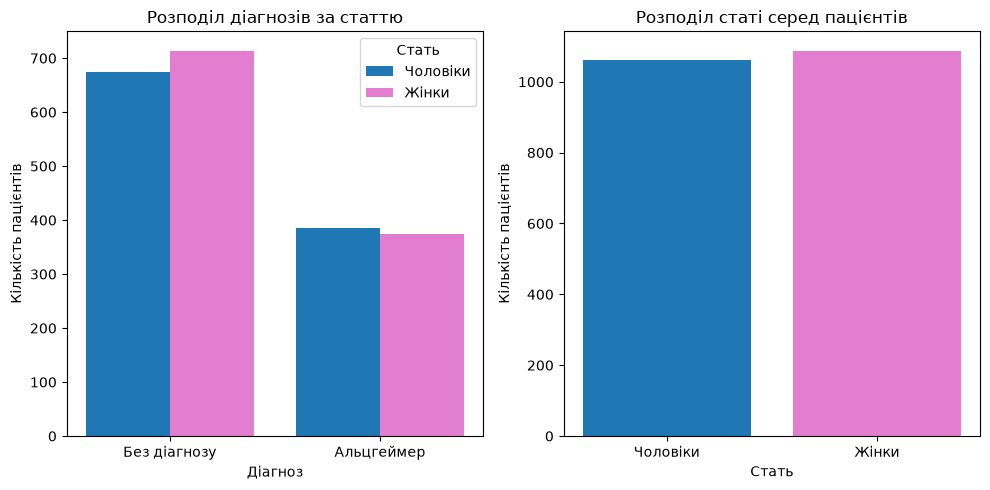

In [4]:
import matplotlib.pyplot as plt

# Діаграма 1: стовпчики — порівняння груп (вісь від нуля)
pivot = df.pivot_table(index='Diagnosis', columns='Gender', aggfunc='size')
pivot.columns = ['Male', 'Female']
pivot.index = ['No Alzheimer\'s', 'Alzheimer\'s']

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].bar(pivot.index, pivot['Male'], label='Чоловіки', color='#1f77b4', width=-0.4, align='edge')
axes[0].bar(pivot.index, pivot['Female'], label='Жінки', color='#e37dcf', width=0.4, align='edge')
axes[0].set_title('Розподіл діагнозів за статтю')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Без діагнозу', 'Альцгеймер'])
axes[0].set_xlabel('Діагноз')
axes[0].set_ylabel('Кількість пацієнтів')
axes[0].legend(title='Стать')
axes[1].bar(pivot.columns, pivot.sum(), color=['#1f77b4', '#e37dcf'])
axes[1].set_title('Розподіл cтаті серед пацієнтів')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Чоловіки', 'Жінки'])
axes[1].set_xlabel('Стать')
axes[1].set_ylabel('Кількість пацієнтів')
plt.tight_layout()
plt.show()


**Крок 4 — висновок 1 (одне речення):** По даному розподілу видно, що кількість пацієнтів з діагнозом Альцгеймера чоловічої статі більша за жіночу, при тому що загальна кількість пацієнтів чоловічої статі менша за кількість пацієнтів жіночої статі у датасеті.

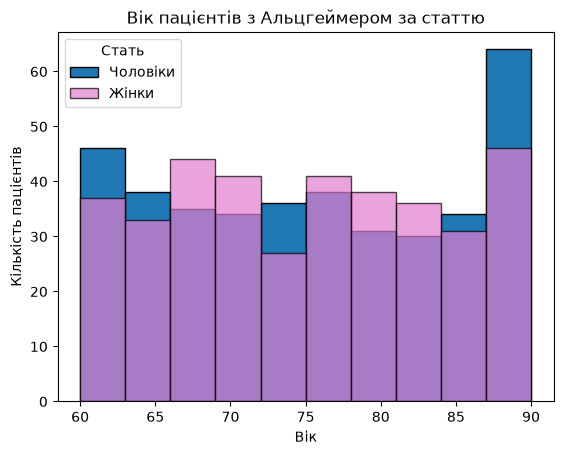

In [5]:
# Діаграма 2: лінія (зміна в часі) або гістограма (розподіл)
alz = df[df['Diagnosis'] == 1]

plt.hist(alz.loc[alz['Gender'] == 0, 'Age'], bins=10,
         label='Чоловіки', color='#1f77b4', edgecolor='black')
plt.hist(alz.loc[alz['Gender'] == 1, 'Age'], bins=10,
         label='Жінки', color='#e37dcf', edgecolor='black', alpha=0.7)
plt.xlabel('Вік')
plt.ylabel('Кількість пацієнтів')
plt.title('Вік пацієнтів з Альцгеймером за статтю')
plt.legend(title='Стать')
plt.show()

**Крок 4 — висновок 2 (одне речення):** У цьому розподілі найбільша частка пацієнтів з діагнозом Альцгеймера віком ближче до 90 років.

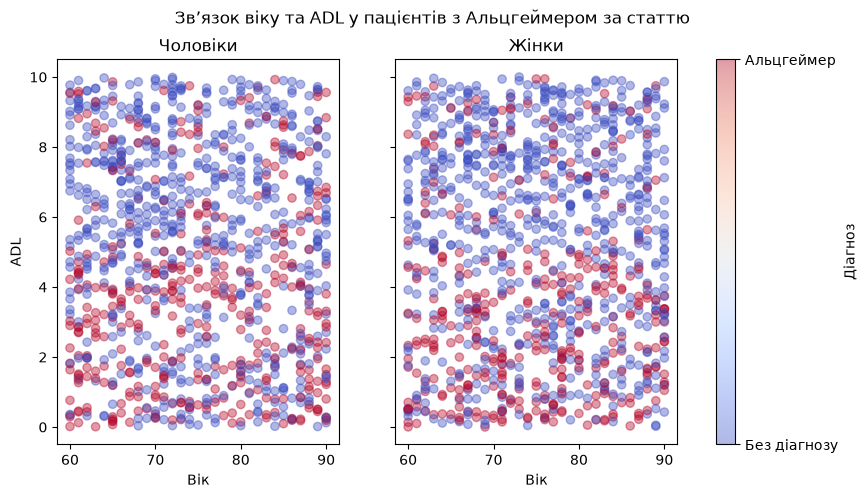

In [6]:
# Діаграма 3: scatter — зв’язок двох чисел
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True, sharex=True)
fig.suptitle('Зв’язок віку та ADL у пацієнтів з Альцгеймером за статтю')
for i, gender in enumerate(df['Gender'].unique()):
    gender_df = df[df['Gender'] == gender]
    sc = axes[i].scatter(gender_df['Age'], gender_df['ADL'],
                         c=gender_df['Diagnosis'], cmap='coolwarm', alpha=0.4)
    axes[i].set_xlabel('Вік')

axes[0].set_title('Чоловіки')
axes[1].set_title('Жінки')
axes[0].set_ylabel('ADL')
fig.colorbar(sc, ax=axes, ticks=[0, 1], label='Діагноз').set_ticklabels(['Без діагнозу', 'Альцгеймер'])
plt.show()

**Крок 4 — висновок 3 (одне речення):** Хоча на цій діаграмі не надто помітно, наскільки більше пацієнтів чоловічої статі з діагнозом Альцгеймера, але можна помітити зв'язок між діагнозом та показником активності у повсякденному житті: у пацієнтів з діагнозом Альцгеймера обох статей частіше зустрічаються нижчі показники активності у будь-якому віці.

## Крок 5. Перевірка однієї діаграми

Яку діаграму перевірили: Вік пацієнтів з Альцгеймером за статтю

- [+] вісь стовпчиків починається від нуля
- [+] є назва й підписи осей
- [+] зрозуміло без пояснень